# Comparing Model Fit with Yellowbrick LearningCurve

Yellowbrick's LearningCurve visualizer shows how a model's training and cross-validation scores change as the amount of training data increases. This example compares two classifiers with different levels of model complexity when used on the same nonlinear dataset.

In this example, Logistic Regression is compared with a Decision Tree model to better understand model complexity. Visualizing learning curves for these two models helps to make underfitting and overfitting more visible, as Logistic Regression is limited by its decision boundary, while the greater flexibility of a Decision Tree can cause it to fit too closely to the training data.


In [1]:
import numpy as np

# Scikit-Learn packages
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# Yellowbrick's LearningCurve visualizer
from yellowbrick.model_selection import LearningCurve


## Dataset

Scikit-learn's make_moons function is utilized to generate a nonlinear dataset with two classes. No download is required as the data is generated locally. The nonlinear class boundary provides a useful comparison between a linear model and a more flexible tree model that can detect nonlinear relationships.

In [ ]:
# Using sci-kit learn's make_moons function to create a 1000 sample nonlinear dataset
x, y = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42,
)

# Checking that the dataset has 1000 samples and 2 classes
print(f"Number of observations: {len(x)}")
print(f"Classes: {np.unique(y)}")


Number of observations: 1000
Classes: [0 1]


## Cross-Validation and Training Sizes

The learning curves use stratified 5-fold cross-validation so that the class distribution is maintained in each fold. Performance of both models is measured at five increasing training set sizes, with 10% to 100% of the available data used during the cross-validation process.

In [ ]:
# Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Define five increasing training set sizes from 10% to 100%
train_sizes = np.linspace(0.1, 1, 5)
train_sizes


array([0.1  , 0.325, 0.55 , 0.775, 1.   ])

## Logistic Regression
First, the learning curve is visualized for Logistic Regression. Logistic Regression learns a linear decision boundary, which results in the model having low flexibility regardless of how much data it is given throughout the cross-validation process.

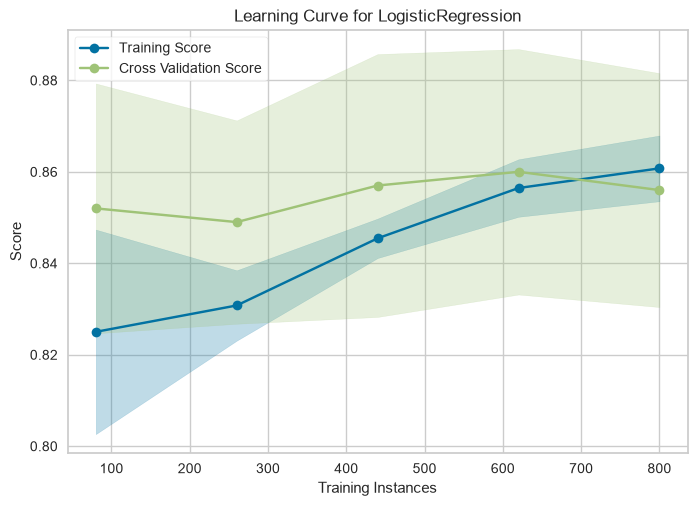

<Axes: title={'center': 'Learning Curve for LogisticRegression'}, xlabel='Training Instances', ylabel='Score'>

In [4]:
# Creating Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
)

# Creating learning curve for Logistic Regression model using LearningCurve
logistic_curve = LearningCurve(
    logistic_model,
    cv=cv,
    scoring="accuracy",
    train_sizes=train_sizes,
)

logistic_curve.fit(x, y)
logistic_curve.show()


The training score and cross-validation scores converge at around 700 training instances and then flatten, ultimately settling at around the same score ~85-86. The crossover at the larger training sizes does not necessarily mean that the model performed better on unseen data than data it was trained on as the crossover fell within the shaded variability band.

The level at which both curves plateau is the most important takeaway from this visualization. The plateau at higher training sizes suggests that the addition of more training data is unlikely to significantly improve performance because Logistic Regression is limited by its linear decision boundary on the nonlinear dataset.

This behavior is consistent with underfitting, since the model appears to be limited by its linear decision boundary rather than the amount of training data available. A more flexible nonlinear model, such as Decision Tree, may better capture the nonlinear class boundary and separation between the two classes.

## Decision Tree

In this instance, the learning curve is visualized for a Decision Tree. The tree can learn a much more flexible decision boundary than Logistic Regression.

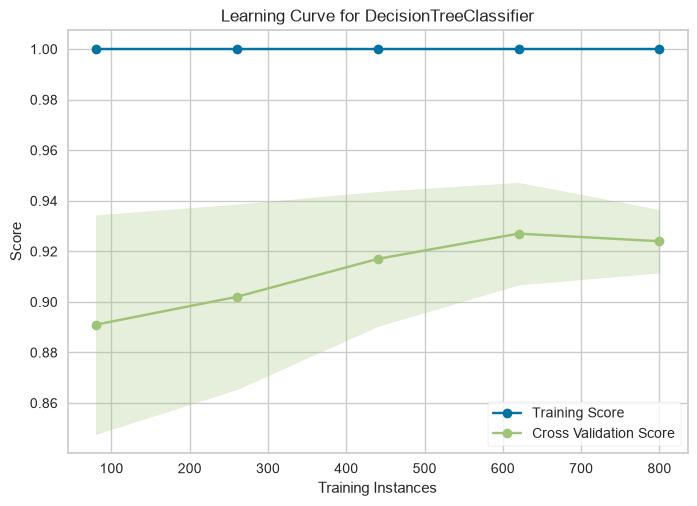

<Axes: title={'center': 'Learning Curve for DecisionTreeClassifier'}, xlabel='Training Instances', ylabel='Score'>

In [5]:

# Creating Decision Tree model
tree_model = DecisionTreeClassifier(
    random_state=42,
)

# Creating the learning curve for Decision Tree model using LearningCurve
tree_curve = LearningCurve(
    tree_model,
    cv=cv,
    scoring="accuracy",
    train_sizes=train_sizes,
)

tree_curve.fit(x, y)
tree_curve.show()


The Decision Tree maintains nearly perfect training performance, while all its cross-validation scores remain consistently lower. The persisting gap between the two curves may be evidence of overfitting, as the model fits the training observations extremely well but does not generalize equally well to unseen folds. However, unlike Logistic Regression, the curves of training and validation do not converge with more training data.

# Conclusion

Yellowbrick's LearningCurve visualizer can show how model complexity affects generalization. A linear model like Logistic Regression produced similar training and validation scores but appeared limited by the nonlinearity of the data, while a more flexible model like Decision Tree achieved stronger training performance at the expense of a larger generalization gap. This application of Yellowbrick's LearningCurve visualizer demonstrates how the tool can be used to identify potential instances of underfitting and overfitting during model selection.